In [ ]:
!pip install -q scikit-learn


In [ ]:
%cd /content/drive/MyDrive/Colab Notebooks/Domain Adaptation

/content/drive/MyDrive/Colab Notebooks/Domain Adaptation


In [ ]:
!python mcd_mobilenetv2.py \
  --isic_path "/content/drive/MyDrive/Colab Notebooks/Domain Adaptation/ISIC2019_merged" \
  --fitz_unlab_path "/content/drive/MyDrive/Colab Notebooks/Domain Adaptation/fitz_unlabeled" \
  --save_dir "/content/drive/MyDrive/mcd_checkpoints2" \
  --epochs 30 \
  --batch_size 16

[INFO] Number of classes: 7
Downloading: "https://download.pytorch.org/models/mobilenet_v2-b0353104.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v2-b0353104.pth
100% 13.6M/13.6M [00:00<00:00, 127MB/s]
Epoch [1/30] Step [0/1567] LossA: 4.090 LossB: -0.066 LossC: 0.051
Epoch [1/30] Step [50/1567] LossA: 1.546 LossB: -0.024 LossC: 0.022
Epoch [1/30] Step [100/1567] LossA: 2.341 LossB: -0.018 LossC: 0.017
Epoch [1/30] Step [150/1567] LossA: 1.709 LossB: -0.014 LossC: 0.012
Epoch [1/30] Step [200/1567] LossA: 1.520 LossB: -0.012 LossC: 0.010
Epoch [1/30] Step [250/1567] LossA: 2.012 LossB: -0.010 LossC: 0.008
Epoch [1/30] Step [300/1567] LossA: 1.275 LossB: -0.010 LossC: 0.007
Epoch [1/30] Step [350/1567] LossA: 1.925 LossB: -0.006 LossC: 0.005
Epoch [1/30] Step [400/1567] LossA: 1.717 LossB: -0.010 LossC: 0.009
Epoch [1/30] Step [450/1567] LossA: 1.832 LossB: -0.014 LossC: 0.012
Epoch [1/30] Step [500/1567] LossA: 1.409 LossB: -0.005 LossC: 0.005
Epoch [1/30] Step [550/1567] LossA:

In [ ]:
!python mcd_mobilenetv2.py \
  --eval_only \
  --fitz_test_path "/content/drive/MyDrive/Colab Notebooks/Domain Adaptation/fitz_selected"\
  --save_dir "/content/drive/MyDrive/mcd_checkpoints2"


[EVAL] Fitzpatrick Accuracy: 26.91%


In [ ]:
import torch
import torch.nn as nn
from torchvision import datasets, transforms, models
from torch.utils.data import DataLoader
import numpy as np

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    precision_recall_fscore_support
)

import matplotlib.pyplot as plt
import seaborn as sns


In [ ]:
class FeatureExtractor(nn.Module):
    def __init__(self):
        super().__init__()
        base = models.mobilenet_v2(
            weights=models.MobileNet_V2_Weights.IMAGENET1K_V1
        )
        self.features = base.features
        self.pool = nn.AdaptiveAvgPool2d(1)

    def forward(self, x):
        x = self.features(x)
        x = self.pool(x)
        return x.view(x.size(0), -1)


In [ ]:
class Classifier(nn.Module):
    def __init__(self, in_dim, num_classes):
        super().__init__()
        self.fc = nn.Linear(in_dim, num_classes)

    def forward(self, x):
        return self.fc(x)


In [ ]:
device = "cuda" if torch.cuda.is_available() else "cpu"


In [ ]:
ckpt_path = "/content/drive/MyDrive/mcd_checkpoints2/mcd_mobilenetv2_best.pth"
ckpt = torch.load(ckpt_path, map_location=device)

num_classes = ckpt["num_classes"]


In [ ]:
G = FeatureExtractor().to(device)
F1 = Classifier(1280, num_classes).to(device)
F2 = Classifier(1280, num_classes).to(device)

G.load_state_dict(ckpt["G"])
F1.load_state_dict(ckpt["F1"])
F2.load_state_dict(ckpt["F2"])

G.eval()
F1.eval()
F2.eval()


Classifier(
  (fc): Linear(in_features=1280, out_features=7, bias=True)
)

In [ ]:
test_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])


In [ ]:
test_root = "/content/drive/MyDrive/Colab Notebooks/Domain Adaptation/fitz_selected"

test_set = datasets.ImageFolder(
    test_root, transform=test_transform
)

test_loader = DataLoader(
    test_set,
    batch_size=32,
    shuffle=False,
    num_workers=0
)


In [ ]:
y_true = []
y_pred = []

with torch.no_grad():
    for x, y in test_loader:
        x = x.to(device)

        feat = G(x)
        logits = (F1(feat) + F2(feat)) / 2
        preds = logits.argmax(dim=1).cpu().numpy()

        y_pred.extend(preds)
        y_true.extend(y.numpy())


In [ ]:
y_true = np.array(y_true)
y_pred = np.array(y_pred)


In [ ]:
acc = accuracy_score(y_true, y_pred)
print(f"Accuracy: {acc*100:.2f}%")


Accuracy: 26.91%


In [ ]:
report = classification_report(
    y_true,
    y_pred,
    target_names=test_set.classes,
    digits=4
)

print(report)


              precision    recall  f1-score   support

          ak     0.0870    0.0114    0.0202       175
         bcc     0.5813    0.2860    0.3834       500
         bkl     0.0408    0.1739    0.0661        69
          df     0.2857    0.0253    0.0465        79
         mel     0.3521    0.3260    0.3385       500
          nv     0.1998    0.8178    0.3211       236
         scc     0.6500    0.0780    0.1393       500

    accuracy                         0.2691      2059
   macro avg     0.3138    0.2455    0.1879      2059
weighted avg     0.4271    0.2691    0.2517      2059



In [ ]:
cm = confusion_matrix(y_true, y_pred)


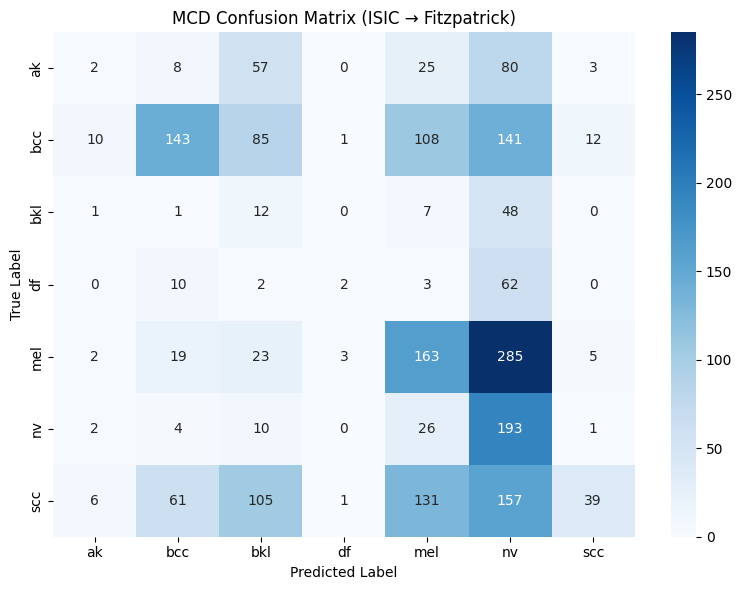

In [ ]:
plt.figure(figsize=(8, 6))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=test_set.classes,
    yticklabels=test_set.classes
)
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("MCD Confusion Matrix (ISIC → Fitzpatrick)")
plt.tight_layout()
plt.show()


In [ ]:
class_names = test_set.classes
num_classes = len(class_names)


In [ ]:
import torch.nn.functional as F
samples = {i: [] for i in range(num_classes)}
max_samples_per_class = 5



In [ ]:
with torch.no_grad():
    for x, y in test_loader:
        x = x.to(device)

        feat = G(x)
        logits = (F1(feat) + F2(feat)) / 2
        probs = F.softmax(logits, dim=1)
        preds = probs.argmax(dim=1)

        for i in range(x.size(0)):
            true_label = y[i].item()
            pred_label = preds[i].item()
            confidence = probs[i, pred_label].item()

            if len(samples[true_label]) < max_samples_per_class:
                samples[true_label].append({
                    "image": x[i].cpu(),
                    "true": true_label,
                    "pred": pred_label,
                    "conf": confidence
                })

        if all(len(samples[c]) >= max_samples_per_class for c in samples):
            break


In [ ]:
def denormalize(img):
    mean = torch.tensor([0.485, 0.456, 0.406]).view(3,1,1)
    std = torch.tensor([0.229, 0.224, 0.225]).view(3,1,1)
    return img * std + mean


In [ ]:
import matplotlib.pyplot as plt
def visualize_per_class(samples, class_names):
    num_classes = len(class_names)
    fig, axes = plt.subplots(num_classes, max_samples_per_class,
                             figsize=(max_samples_per_class*3, num_classes*3))

    for cls_idx, cls_name in enumerate(class_names):
        for j, sample in enumerate(samples[cls_idx]):
            img = denormalize(sample["image"]).permute(1, 2, 0).numpy()
            true_label = class_names[sample["true"]]
            pred_label = class_names[sample["pred"]]
            conf = sample["conf"]

            ax = axes[cls_idx, j]
            ax.imshow(img)
            ax.axis("off")

            color = "green" if sample["true"] == sample["pred"] else "red"
            ax.set_title(
                f"T: {true_label}\nP: {pred_label}\n({conf:.2f})",
                color=color,
                fontsize=10
            )

        # Label row
        axes[cls_idx, 0].set_ylabel(cls_name, fontsize=12)

    plt.tight_layout()
    plt.show()


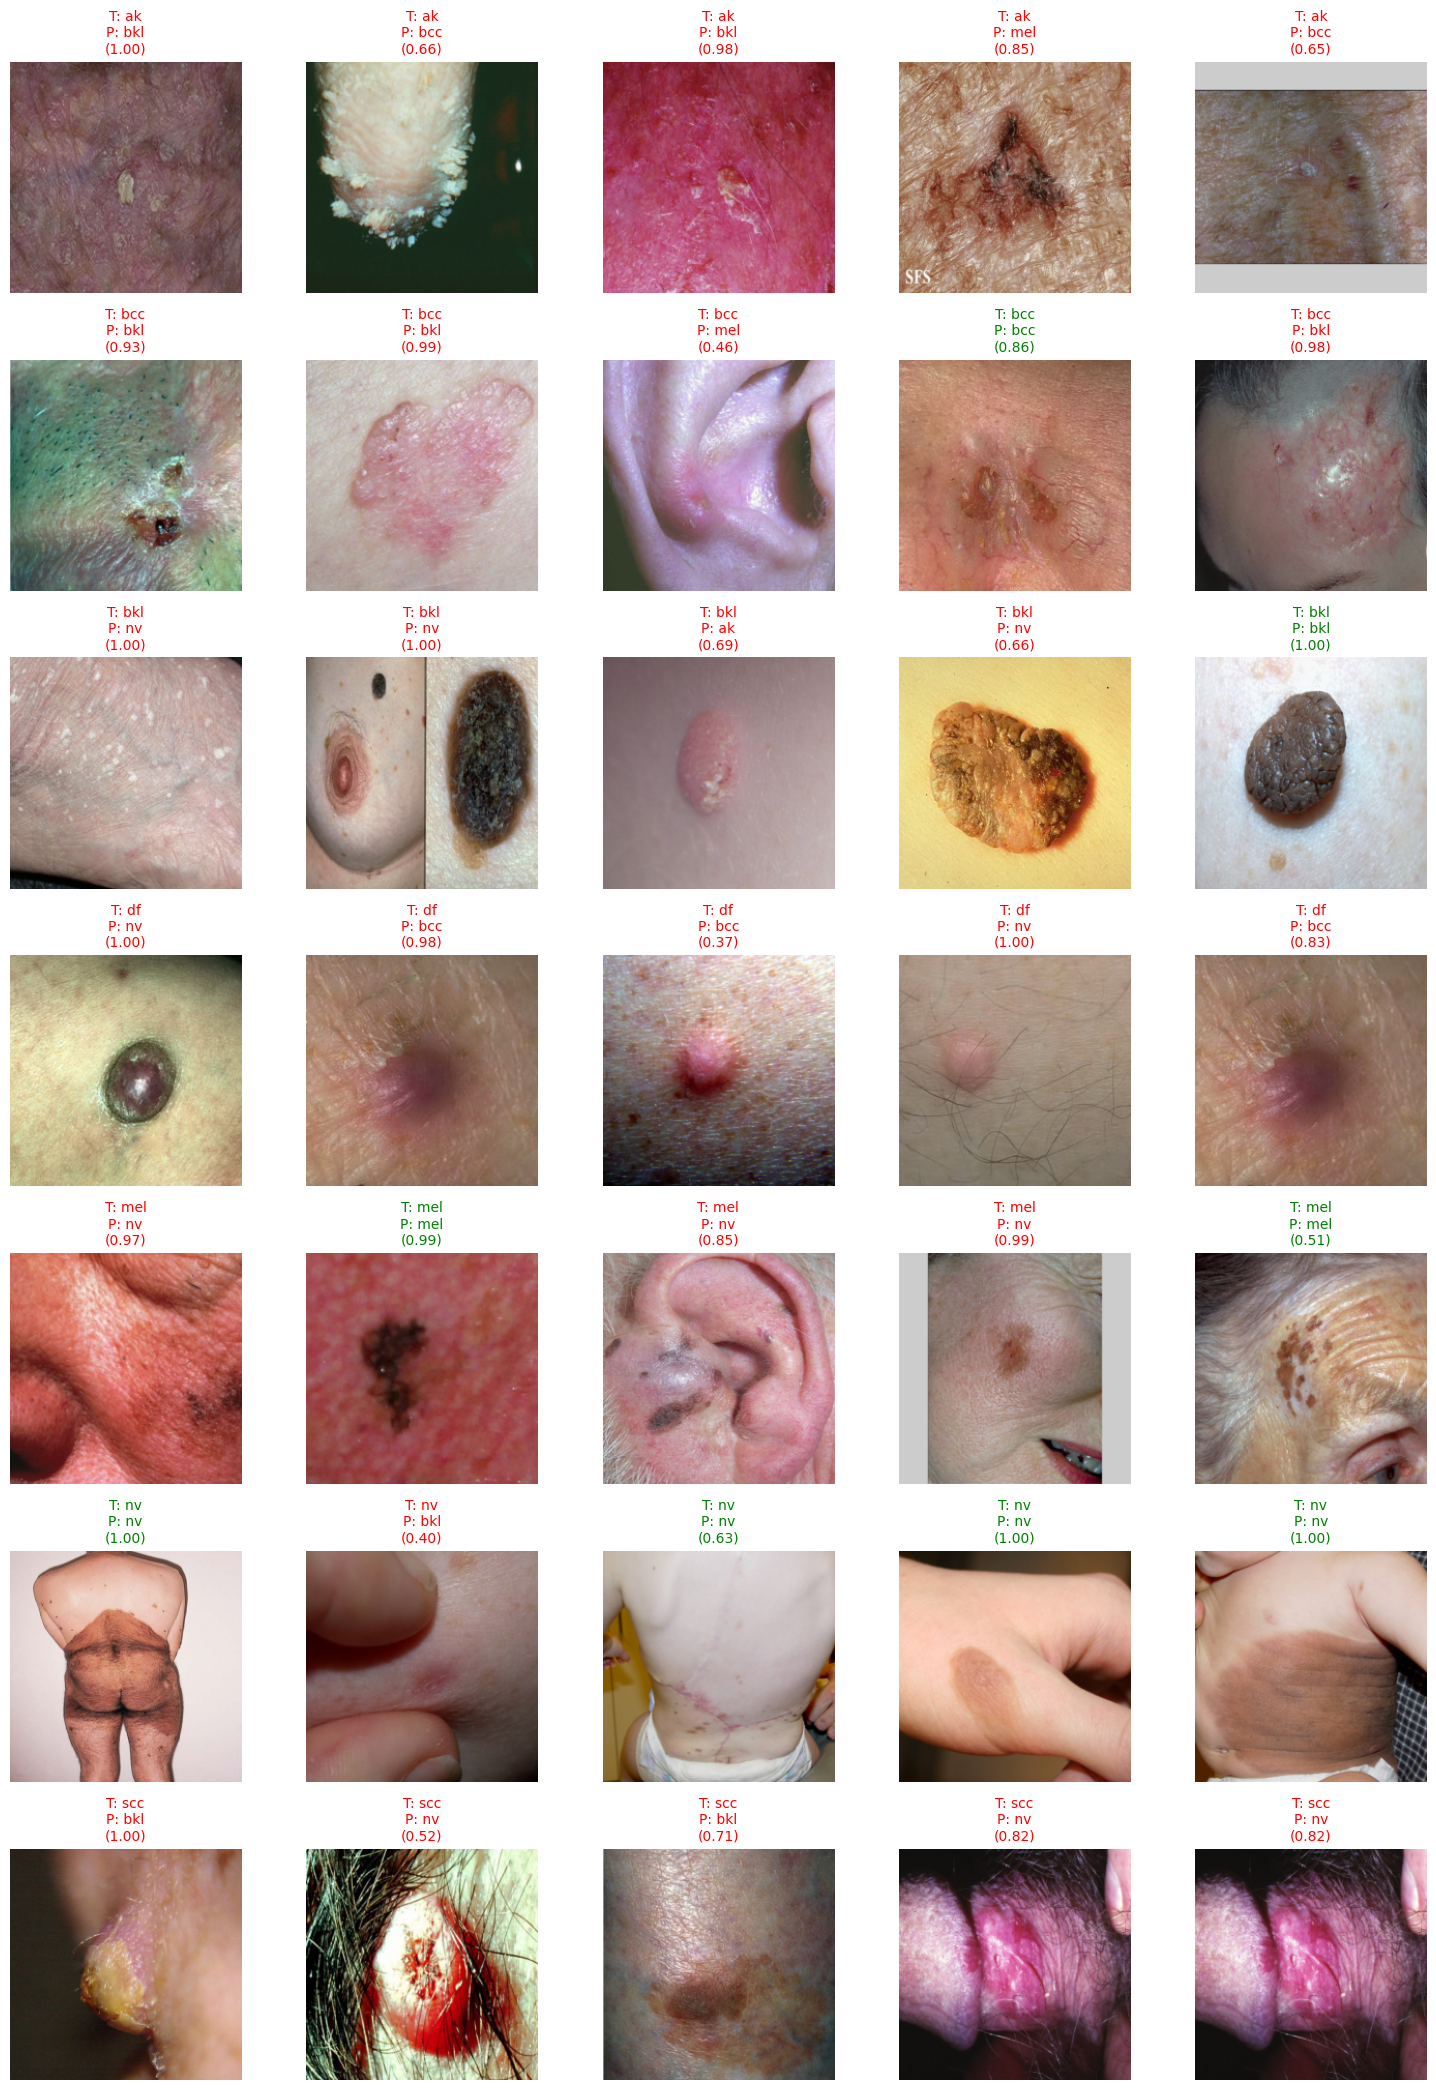

In [ ]:
visualize_per_class(samples, class_names)
